In [1]:
from sklearn.preprocessing import PowerTransformer

In [2]:
#from google.colab import drive
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import boxcox


# drive.mount('/content/drive')

# file_path = '/content/drive/My Drive/Colab Notebooks/Data/bank-additional-full.csv'
file_path = 'D:/ICT_kerala/Data/bank-additional-full.csv'

df_original = pd.read_csv(file_path)
df = df_original.copy()
df.head(2)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [4]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


Identifying duplicate records

In [5]:
print(df.duplicated().sum())

12


Removing duplicate records

In [6]:
df.drop_duplicates(inplace=True)

Checking null values

In [7]:
df.isna().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Identifying categorical features

In [8]:
df_categorical = df.select_dtypes("object")
df_categorical.head(3)

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent,no
1,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent,no
2,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent,no


Identifying numerical features

In [9]:
df_numerical = df.select_dtypes("number")
df_numerical.head(3)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,56,261,1,999,0,1.1,93.994,-36.4,4.857,5191.0
1,57,149,1,999,0,1.1,93.994,-36.4,4.857,5191.0
2,37,226,1,999,0,1.1,93.994,-36.4,4.857,5191.0


Checking total number of unknown values in categorical columns

In [10]:

df_categorical[df_categorical == 'unknown'].count()

job             330
marital          80
education      1730
default        8596
housing         990
loan            990
contact           0
month             0
day_of_week       0
poutcome          0
y                 0
dtype: int64

Checking the percentage of values in the target y

In [11]:
df["y"].value_counts(normalize=True) * 100 # value percentage shows data is highly imbalanced

y
no     88.733728
yes    11.266272
Name: proportion, dtype: float64

<Axes: ylabel='count'>

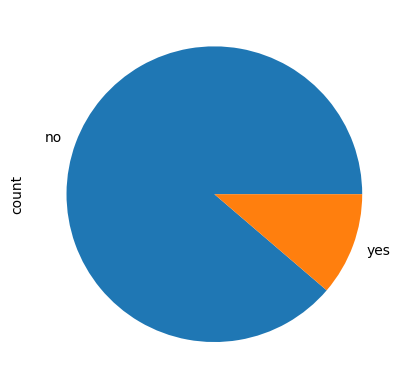

In [12]:
df["y"].value_counts().plot.pie()

# **Feature selection**

All the features seems relevent for the bank marketing campeaign

# **Handling Unknown Values**

In [13]:
# Imputing unknown values with mode
mode_job = df['job'].mode()[0]
df['job'] = df['job'].replace('unknown', mode_job)
mode_marital = df['marital'].mode()[0]
df['marital'] = df['marital'].replace('unknown', mode_marital)
mode_education = df['education'].mode()[0]
df['education'] = df['education'].replace('unknown', mode_education)

In [14]:
#Getting the mode for column default
mode_default = df['default'].mode()[0]
mode_default

'no'

In [15]:
# Checking if there is observations with loan default value unknown and there is no housing and personal loans
len(df[((df['default'] == 'unknown') & (df['housing'] == 'no') & (df['loan'] == 'no'))])

3456

In [16]:
# In the case of no loans, we can add credit default to no
df.loc[(df['default'] == 'unknown') & (df['housing'] == 'no') & (df['loan'] == 'no'), 'default'] = 'no'

In [17]:
# Checking remaining unknown value count for default column
len(df[(df['default'] == 'unknown')])

5140

In [18]:
#Imputing remaining unknow values in default column with mode
df['default'] = df['default'].replace('unknown', mode_default)

In [19]:
#Imputing housing and loan with mode
mode_housing = df['housing'].mode()[0]
df['housing'] = df['housing'].replace('unknown', mode_housing)
mode_loan = df['loan'].mode()[0]
df['loan'] = df['loan'].replace('unknown', mode_loan)

In [20]:
df[df == 'unknown'].count()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

# **Box Plot**

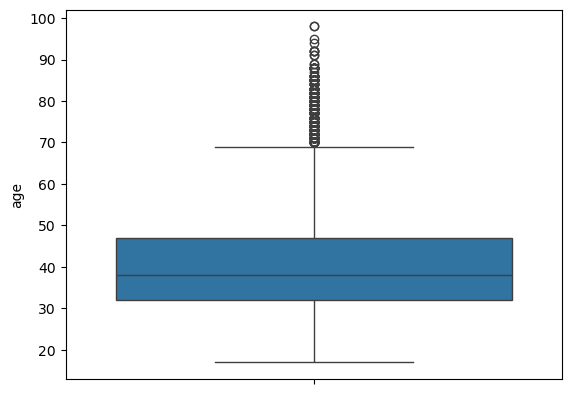

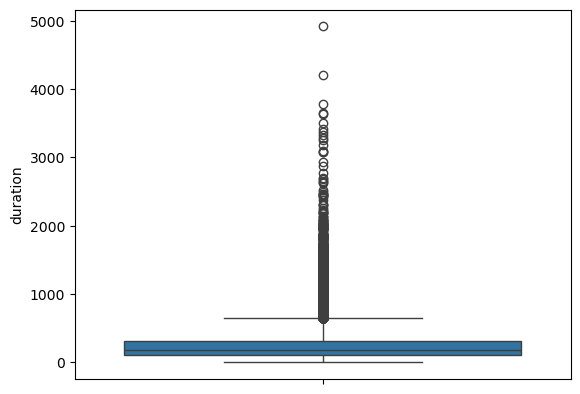

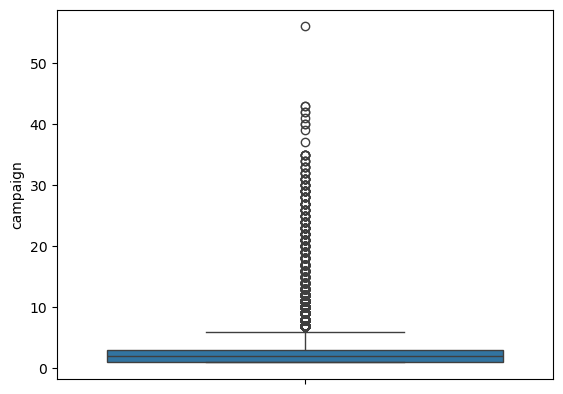

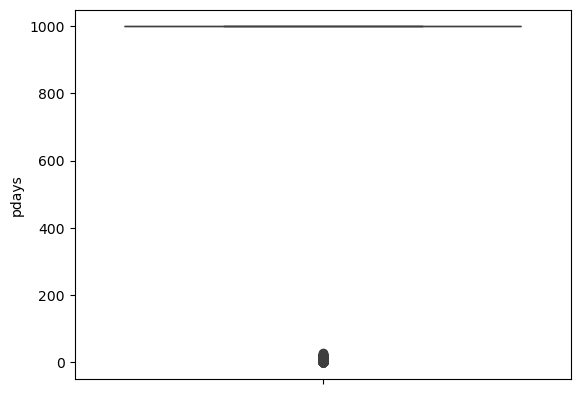

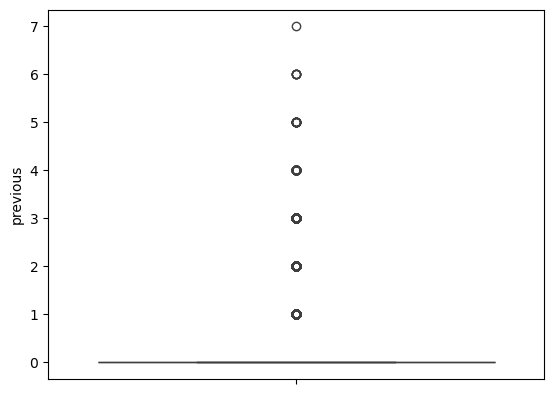

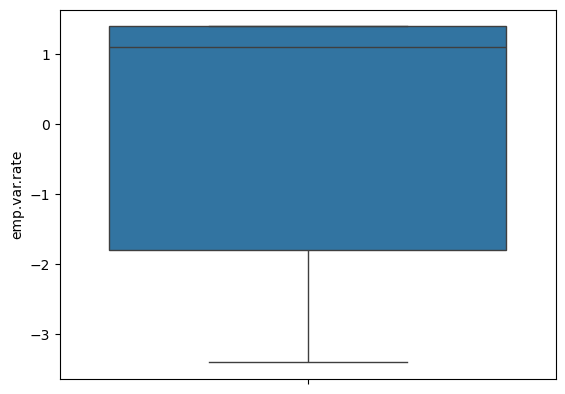

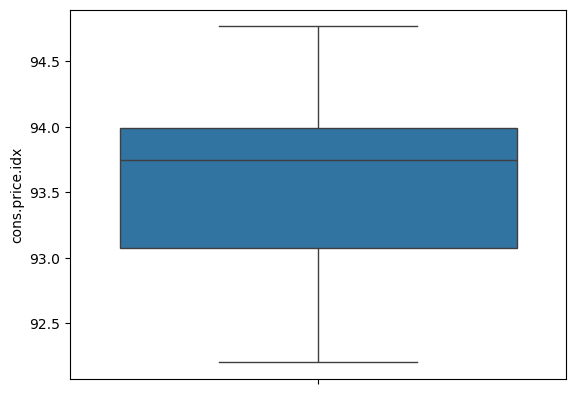

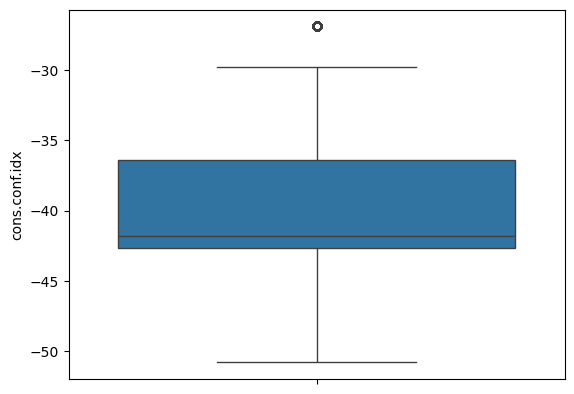

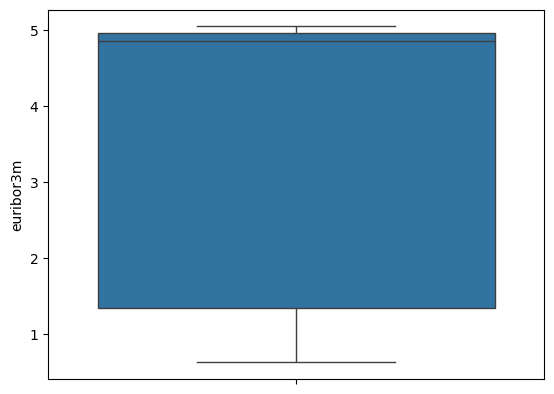

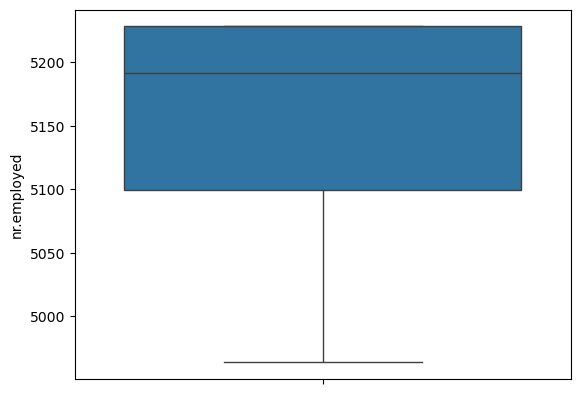

In [21]:
numerical_coumns_df = df.select_dtypes("number")
for i in numerical_coumns_df:
  sns.boxplot(numerical_coumns_df[i])
  plt.show()

There is outliers in the age, duration, campaign, pdays, previous

# **Handling Outliers**

In [22]:
def remove_outliers(df, *columns):
    df_filtered = df  # Make a copy of the original DataFrame

    for i in columns:
        Q1 = df[i].quantile(0.25)
        Q3 = df[i].quantile(0.75)
        IQR = Q3 - Q1

        lower_whisker = Q1 - 1.5 * IQR
        upper_whisker = Q3 + 1.5 * IQR

        # Filter out rows where column values are outliers
        df_filtered = df_filtered[(df_filtered[i] >= lower_whisker) & (df_filtered[i] <= upper_whisker)]

    return df_filtered
remove_outliers(df, "age", "duration", "campaign", "pdays", "previous")

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41180,36,admin.,married,university.degree,no,no,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41181,37,admin.,married,university.degree,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no


# **KDE Plot**

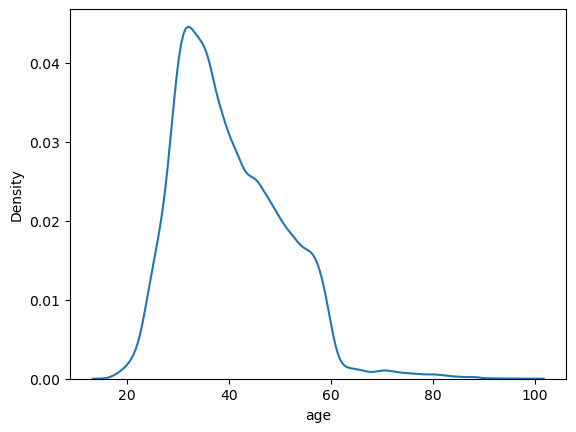

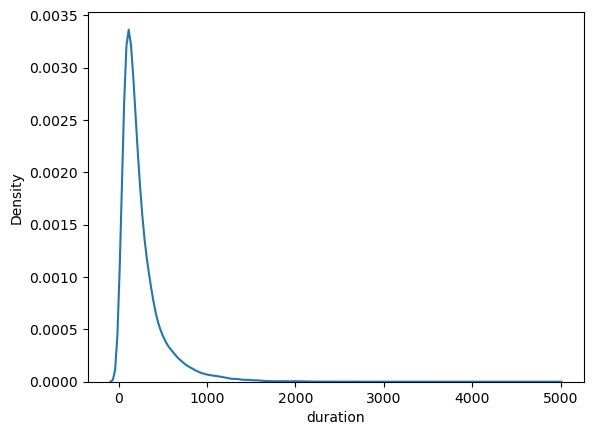

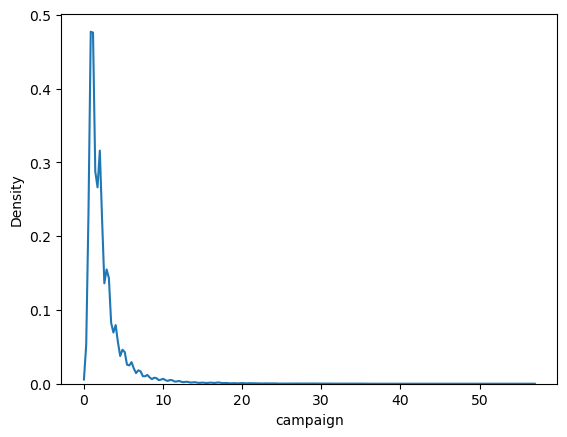

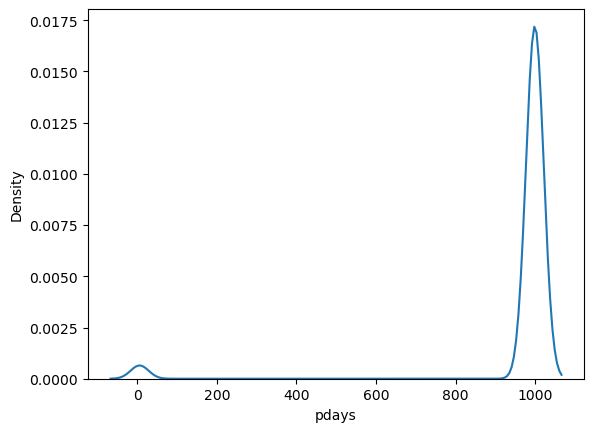

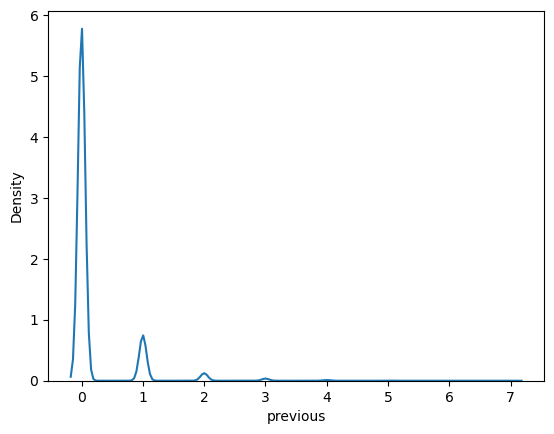

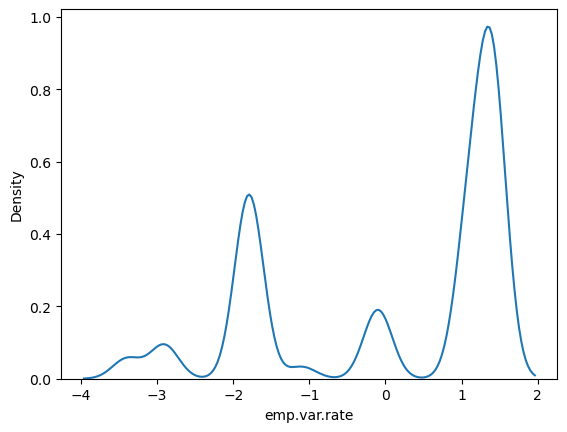

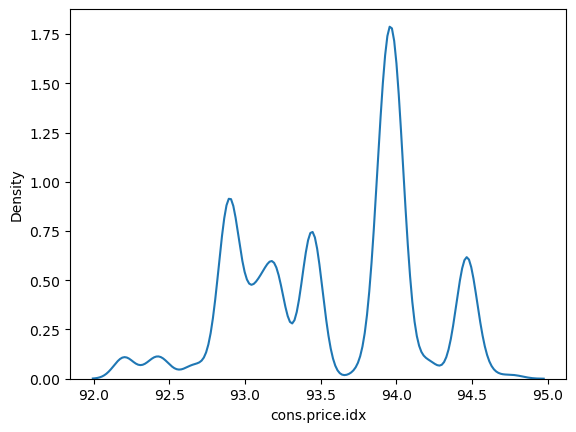

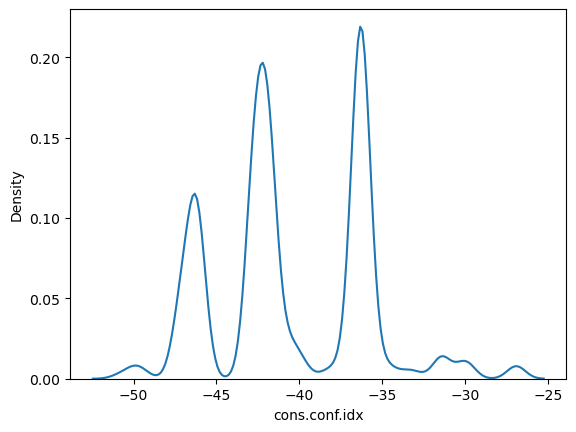

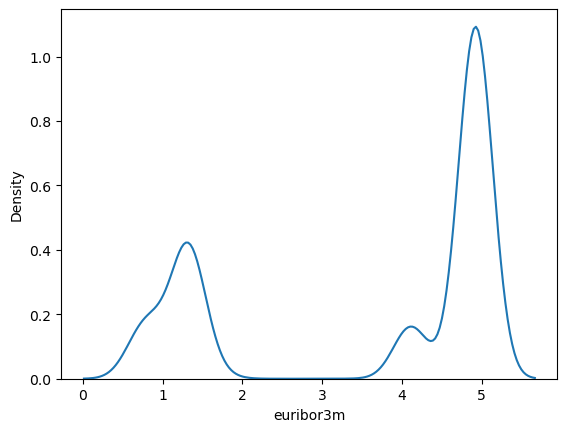

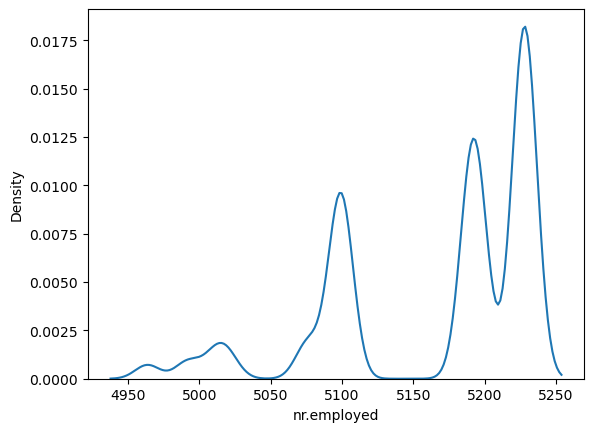

In [23]:
numerical_coumns_df = df.select_dtypes("number")
for i in numerical_coumns_df:
  sns.kdeplot(numerical_coumns_df[i])
  plt.show()

# Finding skewness

In [24]:
df.select_dtypes("number").skew().sort_values(ascending=False)

campaign          4.762044
previous          3.831396
duration          3.262808
age               0.784560
cons.conf.idx     0.302876
cons.price.idx   -0.230853
euribor3m        -0.709194
emp.var.rate     -0.724061
nr.employed      -1.044317
pdays            -4.921386
dtype: float64

Handling Skewness

Applying transformations for reducing skewness - Checking possible transformations of a feature and choosing which is closer to value 0

In [25]:
df['campaign_Log'] = np.log1p(df['campaign'])
df['campaign_Reciprocal'] = 1 / (df['campaign'] + 1e-9)
df['campaign_BoxCox'], _ = boxcox(df['campaign'] + 1e-9)

print(f"Log: {df['campaign_Log'].skew()}")
print(f"Reciprocal: {df['campaign_Reciprocal'].skew()}")
print(f"BoxCox: {df['campaign_BoxCox'].skew()}")
print(f"campaign: {df['campaign'].skew()}")

Log: 1.3502653832482818
Reciprocal: -0.02817636597971296
BoxCox: 0.20587760981479084
campaign: 4.76204406111779


In [26]:
df.drop(["campaign_Log","campaign_BoxCox","campaign"], axis=1, inplace=True) # Choosing Reciprocal because it is more closer to 0

In [27]:
df['previous_Log'] = np.log1p(df['previous'])
df['previous_Reciprocal'] = 1 / (df['previous'] + 1e-9)
df['previous_BoxCox'], _ = boxcox(df['previous'] + 1e-9)

print(f"Log: {df['previous_Log'].skew()}")
print(f"Reciprocal: {df['previous_Reciprocal'].skew()}")
print(f"BoxCox: {df['previous_BoxCox'].skew()}")
print(f"previous: {df['previous'].skew()}")

Log: 2.586510561840952
Reciprocal: -2.116300423740982
BoxCox: 2.1163004516745065
previous: 3.831395514122408


In [28]:
df.drop(["previous_Log","previous_Reciprocal","previous"], axis=1, inplace=True)

In [29]:
df['duration_Log'] = np.log1p(df['duration'])
df['duration_Reciprocal'] = 1 / (df['duration'] + 1e-9)
df['duration_BoxCox'], _ = boxcox(df['duration'] + 1e-9)

print(f"Log: {df['duration_Log'].skew()}")
print(f"Reciprocal: {df['duration_Reciprocal'].skew()}")
print(f"BoxCox: {df['duration_BoxCox'].skew()}")
print(f"duration: {df['duration'].skew()}")

Log: -0.4214987793994195
Reciprocal: 101.44826231704191
BoxCox: 0.04590282464918925
duration: 3.262807509494723


In [30]:
df.drop(["duration_Log","duration_Reciprocal","duration"], axis=1, inplace=True)

In [31]:
df['age_CubeRoot'] = np.cbrt(df['age'])
df['age_BoxCox'], _ = boxcox(df['age'] + 1e-9)

print(f"CubeRoot: {df['age_CubeRoot'].skew()}")
print(f"BoxCox: {df['age_BoxCox'].skew()}")
print(f"age: {df['age'].skew()}")

CubeRoot: 0.33353722498384386
BoxCox: 0.006409439500780018
age: 0.7845602604159752


In [32]:
df.drop(["age_CubeRoot","age"], axis=1, inplace=True)

In [33]:
df['euribor3m_Square'] = df['euribor3m'] ** 2
df['euribor3m_YeoJohnson'] = PowerTransformer(method='yeo-johnson').fit_transform(df[['euribor3m']])

print(f"Square: {df['euribor3m_Square'].skew()}")
print(f"YeoJohnson: {df['euribor3m_YeoJohnson'].skew()}")
print(f"euribor3m: {df['euribor3m'].skew()}")


Square: -0.6339932876058114
YeoJohnson: -0.6498177546261981
euribor3m: -0.7091942125590558


In [34]:
df.drop(["euribor3m_YeoJohnson","euribor3m"], axis=1, inplace=True)

In [35]:
df['emp.var.rate_Square'] = df['emp.var.rate'] ** 2
df['emp.var.rate_YeoJohnson'] = PowerTransformer(method='yeo-johnson').fit_transform(df[['emp.var.rate']])

print(f"Square: {df['emp.var.rate_Square'].skew()}")
print(f"YeoJohnson: {df['emp.var.rate_YeoJohnson'].skew()}")
print(f"emp.var.rate: {df['emp.var.rate'].skew()}")


Square: 2.5610486575459235
YeoJohnson: -0.414203064382135
emp.var.rate: -0.7240605917385116


In [36]:
df.drop(["emp.var.rate_Square","emp.var.rate"], axis=1, inplace=True)

In [37]:
df['nr.employed_Exp'] = np.exp(df['nr.employed'])
df['nr.employed_Square'] = df['nr.employed'] ** 2

print(f"Expon: {df['nr.employed_Exp'].skew()}")
print(f"Square: {df['nr.employed_Square'].skew()}")
print(f"nr.employed: {df['nr.employed'].skew()}")

Expon: nan
Square: -1.025289549487289
nr.employed: -1.0443170571755054


c:\Users\anilk\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\anilk\anaconda3\Lib\site-packages\pandas\core\nanops.py:1256: RuntimeWarning: invalid value encountered in subtract
  adjusted = values - mean


In [38]:
df.drop(["nr.employed_Exp","nr.employed"], axis=1, inplace=True)

In [39]:
df['pdays_YeoJohnson'] = PowerTransformer(method='yeo-johnson').fit_transform(df[['pdays']])
df['pdays_Cube'] = np.power(df['pdays'], 3)

print(f"YeoJohnson: {df['pdays_YeoJohnson'].skew()}")
print(f"Cube: {df['pdays_Cube'].skew()}")
print(f"pdays: {df['pdays'].skew()}")

YeoJohnson: -4.921264181438755
Cube: -4.921264181453764
pdays: -4.921386382079702


In [40]:
df.drop(["pdays_Cube","pdays"], axis=1, inplace=True)

# **Encoding**

In [41]:
df.select_dtypes('object').nunique()

job            11
marital         3
education       7
default         2
housing         2
loan            2
contact         2
month          10
day_of_week     5
poutcome        3
y               2
dtype: int64

Here considering more than 10 unique values as high cardinality

Target (y) -> Label Encoding

job	11 (Nominal) -> Target Encoding

marital	3 (Nominal) -> One hot

education	7 (Ordinal) -> Ordinal Encoding

default	2 (Nominal) -> One hot

housing	2 (Nominal) -> One hot

loan	2 (Nominal) -> One hot

contact	2 (Nominal) -> One hot

month	10 (Nominal) -> Target Encoding

day_of_week	5 (Nominal) -> One hot

poutcome	3 (Nominal) -> One hot

In [42]:
# Label encoding for target
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['y_enc'] = le.fit_transform(df['y'])
df.drop('y', axis=1, inplace=True)

In [43]:
#Target encoding
job_means = df.groupby('job')['y_enc'].mean()
df['target_enc_job'] = df['job'].map(job_means)
df.drop('job', axis=1, inplace=True)

month_means = df.groupby('month')['y_enc'].mean()
df['target_enc_month'] = df['month'].map(month_means)
df.drop('month', axis=1, inplace=True)

**One Hot Encoding**

In [44]:
from sklearn.preprocessing import OneHotEncoder
onehot_columns = ['marital','default','housing', 'loan', 'contact','day_of_week','poutcome']

encoder = OneHotEncoder(drop='first', sparse_output=False)

encoded = encoder.fit_transform(df[onehot_columns])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(onehot_columns),
    index=df.index,
)

df_encoded = pd.concat([df.drop(columns=onehot_columns), encoded_df], axis=1)
df_encoded.head()

,education,cons.price.idx,cons.conf.idx,campaign_Reciprocal,previous_BoxCox,duration_BoxCox,age_BoxCox,euribor3m_Square,emp.var.rate_YeoJohnson,nr.employed_Square,...,default_yes,housing_yes,loan_yes,contact_telephone,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,basic.4y,93.994,-36.4,1.0,-3945.551286,8.731766,2.792155,23.590449,0.561033,26946481.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
1,high.school,93.994,-36.4,1.0,-3945.551286,7.483931,2.800236,23.590449,0.561033,26946481.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
2,high.school,93.994,-36.4,1.0,-3945.551286,8.401081,2.594779,23.590449,0.561033,26946481.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
3,basic.6y,93.994,-36.4,1.0,-3945.551286,7.512399,2.633133,23.590449,0.561033,26946481.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
4,high.school,93.994,-36.4,1.0,-3945.551286,9.113323,2.792155,23.590449,0.561033,26946481.0,...,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0


**Ordinal Encoding**

In [45]:
# education
df_encoded["education"].value_counts()

education
university.degree      13894
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
illiterate                18
Name: count, dtype: int64

In [46]:
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder(categories=[['illiterate','basic.4y','basic.6y','basic.9y','high.school',
                                 'professional.course','university.degree']])
df_encoded['education_enc'] = oe.fit_transform(df_encoded[['education']])
df_encoded.drop('education', axis=1, inplace=True)

# **Scaling**

In [47]:
from sklearn.preprocessing import StandardScaler

scale_columns = ['cons.conf.idx','cons.price.idx']
scaler = StandardScaler()
df_encoded[scale_columns] = scaler.fit_transform(df_encoded[scale_columns])
df_scaled = df_encoded
df_scaled.head(3)

,cons.price.idx,cons.conf.idx,campaign_Reciprocal,previous_BoxCox,duration_BoxCox,age_BoxCox,euribor3m_Square,emp.var.rate_YeoJohnson,nr.employed_Square,pdays_YeoJohnson,...,housing_yes,loan_yes,contact_telephone,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success,education_enc
0,0.722628,0.886568,1.0,-3945.551286,8.731766,2.792155,23.590449,0.561033,26946481.0,0.195445,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
1,0.722628,0.886568,1.0,-3945.551286,7.483931,2.800236,23.590449,0.561033,26946481.0,0.195445,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,4.0
2,0.722628,0.886568,1.0,-3945.551286,8.401081,2.594779,23.590449,0.561033,26946481.0,0.195445,...,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,4.0


**Splitting dataset into training and testing**

In [48]:
df_scaled.columns

Index(['cons.price.idx', 'cons.conf.idx', 'campaign_Reciprocal',
       'previous_BoxCox', 'duration_BoxCox', 'age_BoxCox', 'euribor3m_Square',
       'emp.var.rate_YeoJohnson', 'nr.employed_Square', 'pdays_YeoJohnson',
       'y_enc', 'target_enc_job', 'target_enc_month', 'marital_married',
       'marital_single', 'default_yes', 'housing_yes', 'loan_yes',
       'contact_telephone', 'day_of_week_mon', 'day_of_week_thu',
       'day_of_week_tue', 'day_of_week_wed', 'poutcome_nonexistent',
       'poutcome_success', 'education_enc'],
      dtype='object')

In [49]:
x = df_scaled[['cons.price.idx', 'cons.conf.idx', 'campaign_Reciprocal',
       'previous_BoxCox', 'duration_BoxCox', 'age_BoxCox', 'euribor3m_Square',
       'emp.var.rate_YeoJohnson', 'nr.employed_Square', 'pdays_YeoJohnson',
       'target_enc_job', 'marital_married', 'marital_single',
       'default_yes', 'housing_yes', 'loan_yes', 'contact_telephone',
       'day_of_week_mon', 'day_of_week_thu', 'day_of_week_tue',
       'day_of_week_wed', 'poutcome_nonexistent', 'poutcome_success',
       'education_enc', 'target_enc_month']]
y = df_scaled['y_enc']

x.shape, y.shape

((41176, 25), (41176,))

In [50]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test =train_test_split(x,y,test_size=.2,random_state=42)

x_train.shape, y_train.shape, x_test.shape, y_test.shape


((32940, 25), (32940,), (8236, 25), (8236,))

Logistic Regression

In [51]:
# Applied SMOTE for compensating target class imbalance
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score,precision_score,recall_score,f1_score

smote = SMOTE(random_state=42)
x_train_res, y_train_res = smote.fit_resample(x_train, y_train)

print(f"Y Train orig {y_train.value_counts()}")        # before
print(f"Y Train Resample {y_train_res.value_counts()}")

logreg = LogisticRegression(max_iter=2000)
logreg.fit(x_train_res, y_train_res)

Y Train orig y_enc
0    29272
1     3668
Name: count, dtype: int64
Y Train Resample y_enc
0    29272
1    29272
Name: count, dtype: int64


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [52]:
y_test_pred = logreg.predict(x_test)
y_train_pred = logreg.predict(x_train_res)
y_test_pred

array([1, 1, 1, ..., 0, 0, 0], shape=(8236,))

In [53]:
accuracy_score(y_test,y_test_pred) * 100

83.06216610004856

In [54]:
train_accuracy = accuracy_score(y_train_res, y_train_pred) * 100
test_accuracy = accuracy_score(y_test, y_test_pred) * 100

print(f"Train Accuracy : {train_accuracy}")
print(f"Test Accuracy : {test_accuracy}")

Train Accuracy : 85.52712489751299
Test Accuracy : 83.06216610004856


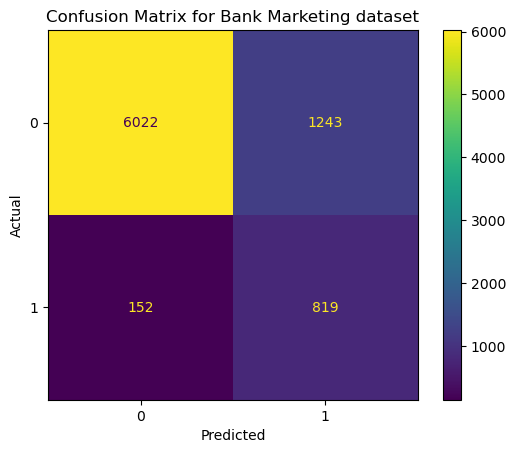

In [55]:
cm=confusion_matrix(y_test, y_test_pred)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Bank Marketing dataset')
plt.show()

In [56]:
# Classification report
from sklearn.metrics import classification_report
cr = classification_report(y_test, y_test_pred)
print("Classification Report:")
print(cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.83      0.90      7265
           1       0.40      0.84      0.54       971

    accuracy                           0.83      8236
   macro avg       0.69      0.84      0.72      8236
weighted avg       0.91      0.83      0.85      8236



# **SVC**

In [57]:
from sklearn.svm import SVC

svm_classifier = SVC()
svm_classifier.fit(x_train_res, y_train_res)


svm_y_pred = svm_classifier.predict(x_test)


accuracy = accuracy_score(y_test,svm_y_pred) * 100
print(f'SVM Accuracy: {accuracy}')

SVM Accuracy: 71.98882952889753


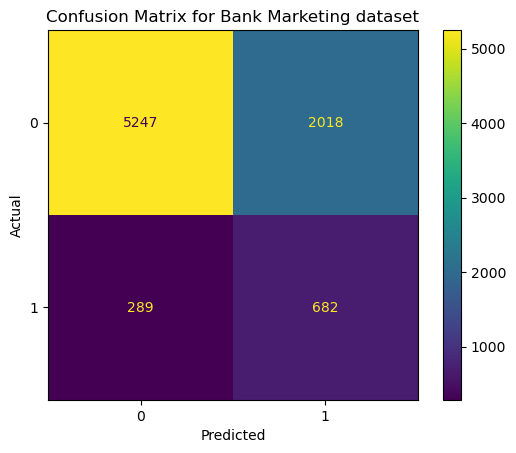

In [58]:
cm=confusion_matrix(y_test, svm_y_pred)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Bank Marketing dataset')
plt.show()

In [59]:
# Classification report
from sklearn.metrics import classification_report
cr = classification_report(y_test, svm_y_pred)
print("Classification Report:")
print(cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.72      0.82      7265
           1       0.25      0.70      0.37       971

    accuracy                           0.72      8236
   macro avg       0.60      0.71      0.60      8236
weighted avg       0.87      0.72      0.77      8236



# **KNN**

In [60]:
from sklearn.neighbors import KNeighborsClassifier

# Create a KNN classifier
knn = KNeighborsClassifier(n_neighbors=20)#tuning (best parameters)

# Fit the model
knn.fit(x_train_res, y_train_res)

,n_neighbors,20
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [61]:
knn_y_pred = knn.predict(x_test)
knn_y_pred

array([1, 0, 1, ..., 0, 0, 0], shape=(8236,))

In [62]:
accuracy_score(y_test,knn_y_pred) * 100

83.97280233122875

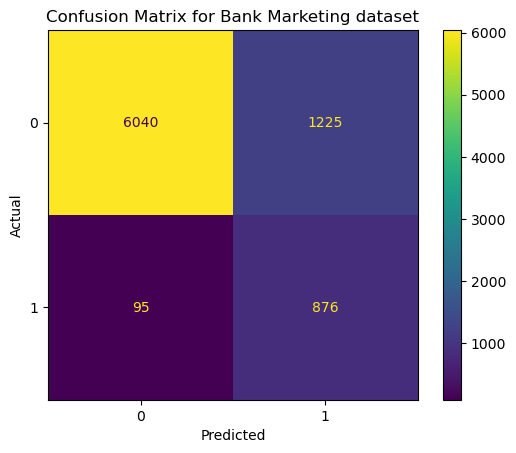

In [63]:
cm=confusion_matrix(y_test, knn_y_pred)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Bank Marketing dataset')
plt.show()

In [64]:
print(classification_report(y_test,knn_y_pred))

              precision    recall  f1-score   support

           0       0.98      0.83      0.90      7265
           1       0.42      0.90      0.57       971

    accuracy                           0.84      8236
   macro avg       0.70      0.87      0.74      8236
weighted avg       0.92      0.84      0.86      8236



# **Decision Tree**

In [65]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(x_train_res, y_train_res)

dt_y_pred = dt.predict(x_test)

print("Accuracy:", accuracy_score(y_test, dt_y_pred) * 100)

Accuracy: 87.76104905293832


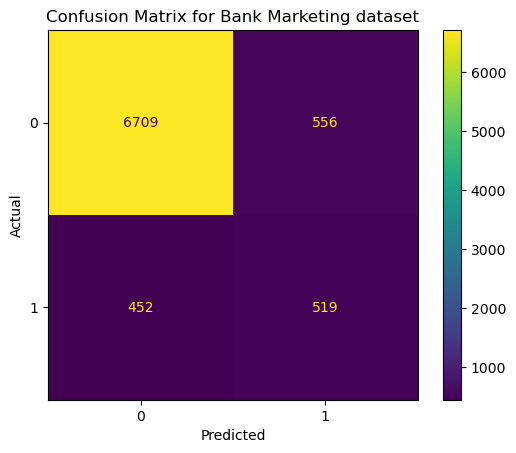

In [66]:
cm=confusion_matrix(y_test, dt_y_pred)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Bank Marketing dataset')
plt.show()

In [67]:
print(classification_report(y_test,dt_y_pred))

              precision    recall  f1-score   support

           0       0.94      0.92      0.93      7265
           1       0.48      0.53      0.51       971

    accuracy                           0.88      8236
   macro avg       0.71      0.73      0.72      8236
weighted avg       0.88      0.88      0.88      8236



# **Ensemble Learning Methods**

# Random Forest

In [68]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(x_train_res, y_train_res)
rf_y_pred = rf.predict(x_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_y_pred) * 100)

Random Forest Accuracy: 90.49295774647888


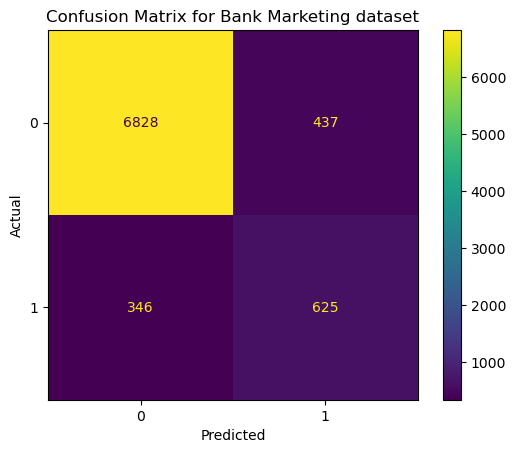

In [69]:
cm=confusion_matrix(y_test, rf_y_pred)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Bank Marketing dataset')
plt.show()

In [70]:
print(classification_report(y_test,rf_y_pred))

              precision    recall  f1-score   support

           0       0.95      0.94      0.95      7265
           1       0.59      0.64      0.61       971

    accuracy                           0.90      8236
   macro avg       0.77      0.79      0.78      8236
weighted avg       0.91      0.90      0.91      8236



## **Bagging**

Bagging with decision tree classifier

In [71]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=42
)

bagging.fit(x_train_res, y_train_res)
bagg_dt_y_pred = bagging.predict(x_test)

print("Bagging Accuracy:", accuracy_score(y_test, bagg_dt_y_pred) * 100)

Bagging Accuracy: 90.46867411364741


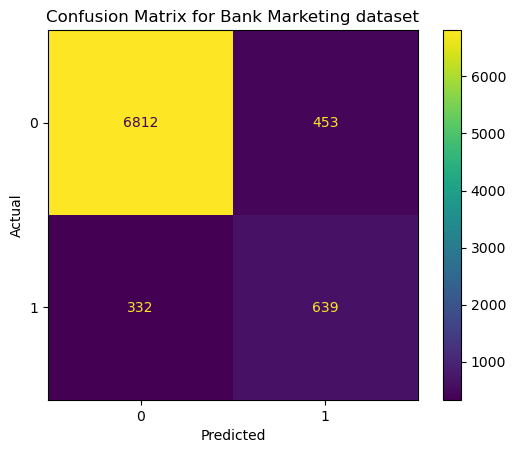

In [72]:
cm=confusion_matrix(y_test, bagg_dt_y_pred)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Bank Marketing dataset')
plt.show()

In [73]:
print(classification_report(y_test,bagg_dt_y_pred))

              precision    recall  f1-score   support

           0       0.95      0.94      0.95      7265
           1       0.59      0.66      0.62       971

    accuracy                           0.90      8236
   macro avg       0.77      0.80      0.78      8236
weighted avg       0.91      0.90      0.91      8236



Bagging with SVC

In [74]:
from sklearn.svm import SVC


bag_svc = BaggingClassifier(
    estimator=SVC(),
    n_estimators=10,
    random_state=42
)


bag_svc.fit(x_train_res, y_train_res)


bagg_svc_y_pred = bag_svc.predict(x_test)


print("Bagging with SVC Accuracy:", accuracy_score(y_test, bagg_svc_y_pred) * 100)

Bagging with SVC Accuracy: 71.98882952889753


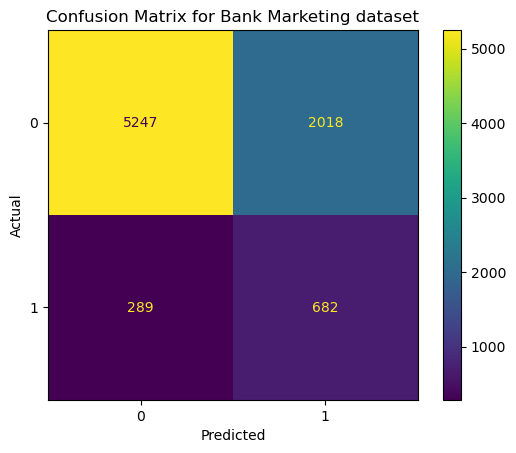

In [75]:
cm=confusion_matrix(y_test, bagg_svc_y_pred)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Bank Marketing dataset')
plt.show()

In [76]:
print(classification_report(y_test,bagg_svc_y_pred))

              precision    recall  f1-score   support

           0       0.95      0.72      0.82      7265
           1       0.25      0.70      0.37       971

    accuracy                           0.72      8236
   macro avg       0.60      0.71      0.60      8236
weighted avg       0.87      0.72      0.77      8236



Bagging with Logistic Regression

In [77]:

bag_svc = BaggingClassifier(
    estimator=LogisticRegression(max_iter=1000),
    n_estimators=10,
    random_state=42
)


bag_svc.fit(x_train_res, y_train_res)


bagg_logi_y_pred = bag_svc.predict(x_test)


print("Bagging with Logistice Regression Accuracy:", accuracy_score(y_test, bagg_logi_y_pred) * 100)

Bagging with Logistice Regression Accuracy: 82.0908207867897


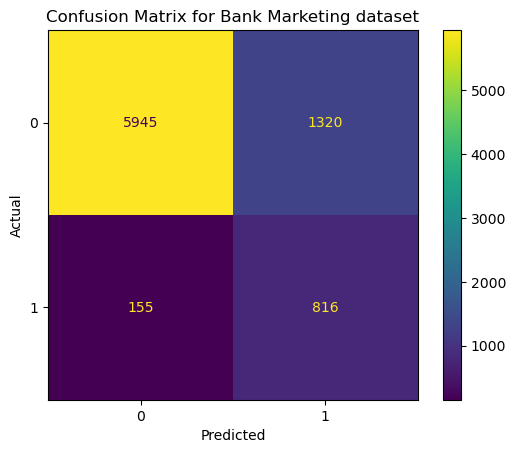

In [78]:
cm=confusion_matrix(y_test, bagg_logi_y_pred)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Bank Marketing dataset')
plt.show()

In [79]:
print(classification_report(y_test,bagg_logi_y_pred))

              precision    recall  f1-score   support

           0       0.97      0.82      0.89      7265
           1       0.38      0.84      0.53       971

    accuracy                           0.82      8236
   macro avg       0.68      0.83      0.71      8236
weighted avg       0.90      0.82      0.85      8236



# **Boosting**

Ada Boosting

In [104]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

ada.fit(x_train_res, y_train_res)
ada_y_pred = ada.predict(x_test)

print("AdaBoost Accuracy:", accuracy_score(y_test, ada_y_pred) * 100)

AdaBoost Accuracy: 85.72122389509471


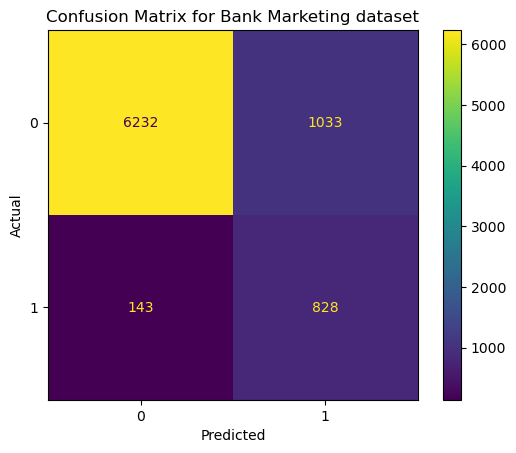

In [105]:
cm=confusion_matrix(y_test, ada_y_pred)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Bank Marketing dataset')
plt.show()

In [106]:
print(classification_report(y_test,ada_y_pred))

              precision    recall  f1-score   support

           0       0.98      0.86      0.91      7265
           1       0.44      0.85      0.58       971

    accuracy                           0.86      8236
   macro avg       0.71      0.86      0.75      8236
weighted avg       0.91      0.86      0.87      8236



Gradient Boosting

In [107]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gb.fit(x_train_res, y_train_res)
grad_boost_y_pred = gb.predict(x_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, grad_boost_y_pred) * 100)

Gradient Boosting Accuracy: 88.75667799902865


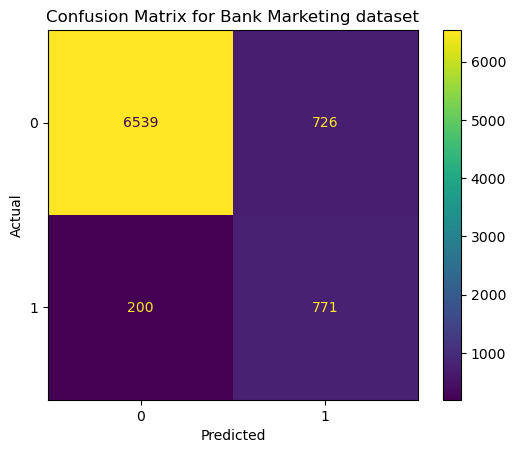

In [108]:
cm=confusion_matrix(y_test, grad_boost_y_pred)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Bank Marketing dataset')
plt.show()

In [109]:
print(classification_report(y_test,grad_boost_y_pred))

              precision    recall  f1-score   support

           0       0.97      0.90      0.93      7265
           1       0.52      0.79      0.62       971

    accuracy                           0.89      8236
   macro avg       0.74      0.85      0.78      8236
weighted avg       0.92      0.89      0.90      8236



| Model | Accuracy Score | target | Precison | Recall | F1-Score |
| --- | --- | --- | --- | --- | --- |
| Logistic Regression | 83.0621 | 0 | 0.98 | 0.83 | 0.90 |
|  | | 1 | 0.40 | 0.84 | 0.54 |
| SVM | 71.9888 | 0 | 0.95 | 0.72 | 0.82 |
|  | | 1 | 0.25 | 0.70 | 0.37 |
| KNN |  83.9728 | 0 | 0.98 | 0.83 | 0.90 |
|  | | 1 | 0.42 | 0.90 | 0.57 |
| Decision Tree | 87.7246 | 0 | 0.94 | 0.92 | 0.93 |
|  | | 1 | 0.48 | 0.54 | 0.51 |
| Random Forest | 90.4929 | 0 | 0.95 | 0.94 | 0.95 |
|  | | 1 | 0.59 | 0.64 | 0.61 |
| Bagging<br>(Decision Tree) | 90.4686 | 0 | 0.95 | 0.94 | 0.95 |
|  | | 1 | 0.59 | 0.66 | 0.62 |
| Bagging<br>(SVC) | 71.9888 | 0 | 0.95 | 0.72 | 0.82 |
|  | | 1 | 0.25 | 0.70 | 0.37 |
| Bagging<br>(Logistic Regr) | 82.0908 | 0 | 0.97 | 0.82 | 0.89 |
|  | | 1 | 0.38 | 0.84 | 0.53 |
| Boosting<br>(Ada Boosting) | 85.7212 | 0 | 0.98 | 0.86 | 0.91 |
|  | | 1 | 0.44 | 0.85 | 0.58 |
| Boosting<br>(Gradient Boosting) | 88.7566 | 0 | 0.97 | 0.90 | 0.93 |
|  | | 1 | 0.52 | 0.79 | 0.62 |

SMOTE method is used to resample the training data to avoid imablanced in the target class. So we can consider the accuracy score for comparion.

Random Forest and Bagging(Decision Tree) have comparatively highest accuracy score (90.49) and precison and recall scores.